<a href="https://colab.research.google.com/github/varsha-sspace/Unemployment-Analysis-with-Python/blob/main/Unemployment_Analysis_India.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!unzip archive.zip

Archive:  archive.zip
replace Unemployment in India.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [5]:
# 1. Strip spaces from column names
df.columns = df.columns.str.strip()

# 2. Rename columns to clean, simple identifiers
df.rename(columns={
    'Region': 'State',
    'Region.1': 'Region',
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
}, inplace=True)

# 3. Check for any missing values
print("Missing values in each column:\n", df.isnull().sum())

# 4. Convert 'Date' to datetime and extract time components
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Month_Name'] = df['Date'].dt.month_name()
df['Month_Num'] = df['Date'].dt.month

# 5. Check cleaned information
df.info()

Missing values in each column:
 State                        0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Region                       0
longitude                    0
latitude                     0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   State                      267 non-null    object        
 1   Date                       267 non-null    datetime64[ns]
 2   Frequency                  267 non-null    object        
 3   Unemployment_Rate          267 non-null    float64       
 4   Employed                   267 non-null    int64         
 5   Labour_Participation_Rate  267 non-null    float64       
 6   Region                     267 non-null    object        
 7  

Descriptive Statistics:


,Unemployment_Rate,Employed,Labour_Participation_Rate
count,267.000000,2.670000e+02,267.000000
mean,12.236929,1.396211e+07,41.681573
std,10.803283,1.336632e+07,7.845419
min,0.500000,1.175420e+05,16.770000
25%,4.845000,2.838930e+06,37.265000
50%,9.650000,9.732417e+06,40.390000
75%,16.755000,2.187869e+07,44.055000
max,75.850000,5.943376e+07,69.690000


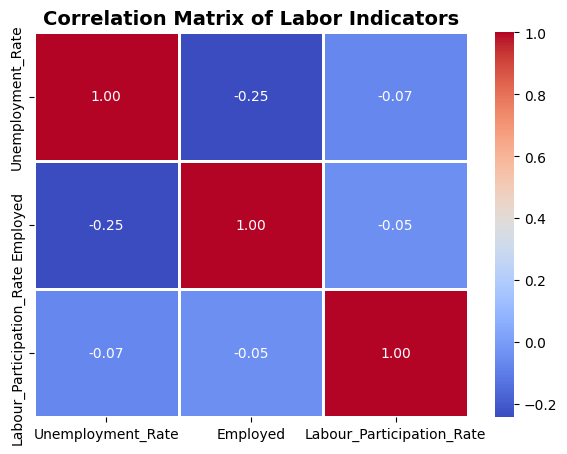

In [6]:
# 1. Summary statistics of the numeric features
print("Descriptive Statistics:")
display(df[['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']].describe())

# 2. Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']].corr(),
            annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.8)
plt.title("Correlation Matrix of Labor Indicators", fontsize=14, weight='bold')
plt.show()

Average Unemployment Rate by Period:
                               Period  Unemployment_Rate
0  Lockdown & Post-Lockdown (Apr-Oct)          13.277128
1              Pre-Lockdown (Jan-Mar)           9.761519


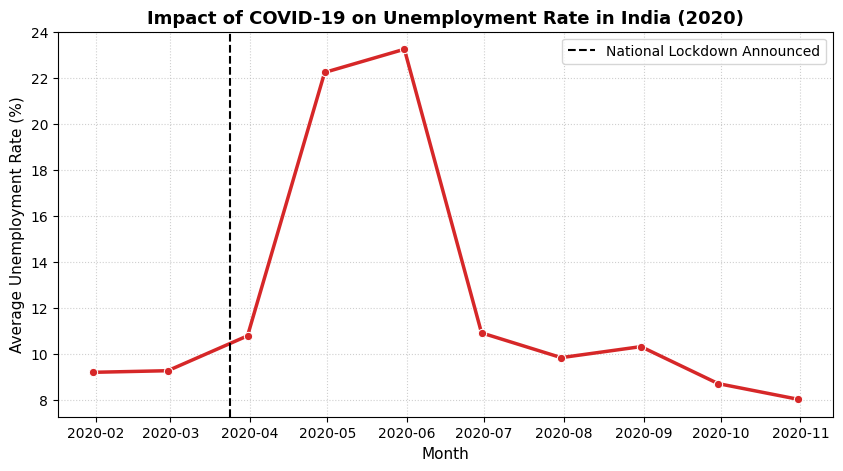

In [7]:
# 1. Segment data into Pre-Lockdown and Lockdown periods
df['Period'] = df['Month_Num'].apply(
    lambda x: 'Pre-Lockdown (Jan-Mar)' if x <= 3 else 'Lockdown & Post-Lockdown (Apr-Oct)'
)

# 2. Compare average unemployment rate before and during lockdown
period_stats = df.groupby('Period')['Unemployment_Rate'].mean().reset_index()
print("Average Unemployment Rate by Period:")
print(period_stats)

# 3. Line plot showing the monthly trend across 2020
monthly_avg = df.groupby('Date')['Unemployment_Rate'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_avg, x='Date', y='Unemployment_Rate', marker='o', color='#d62728', linewidth=2.5)

# Highlight the lockdown announcement date
plt.axvline(pd.to_datetime('2020-03-24'), color='black', linestyle='--', linewidth=1.5, label='National Lockdown Announced')

plt.title("Impact of COVID-19 on Unemployment Rate in India (2020)", fontsize=13, weight='bold')
plt.xlabel("Month", fontsize=11)
plt.ylabel("Average Unemployment Rate (%)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

/tmp/ipykernel_563/1764751150.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_data, x='Region', y='Unemployment_Rate', palette='mako')


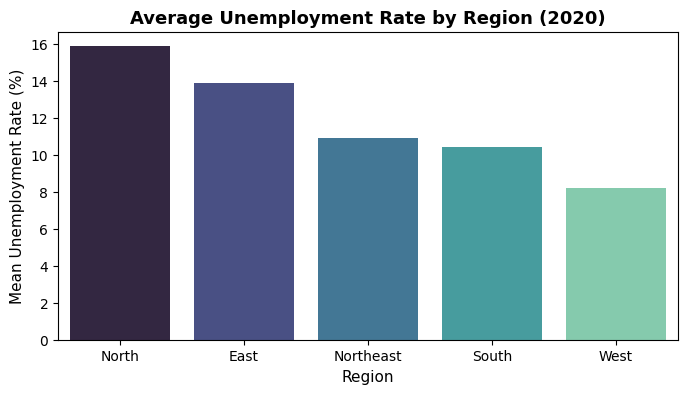

/tmp/ipykernel_563/1764751150.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_states, x='Unemployment_Rate', y='State', palette='rocket')


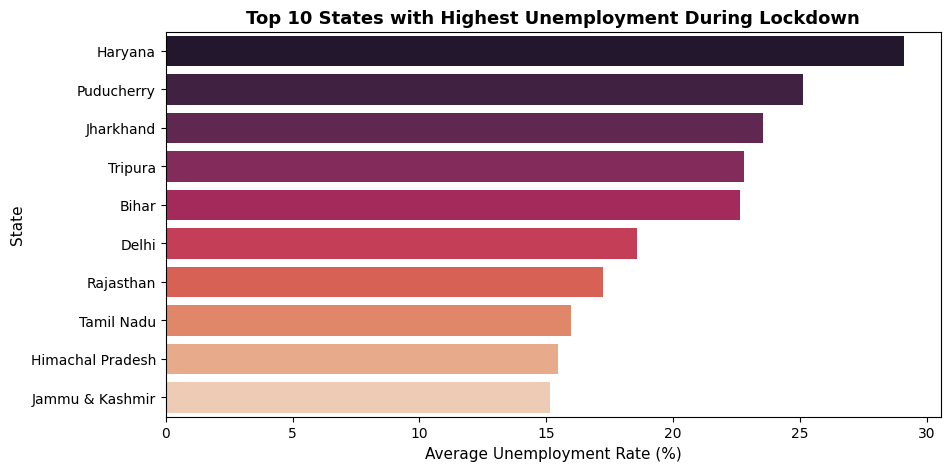

In [8]:
# 1. Regional impact comparison
region_data = df.groupby('Region')['Unemployment_Rate'].mean().reset_index().sort_values(by='Unemployment_Rate', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=region_data, x='Region', y='Unemployment_Rate', palette='mako')
plt.title("Average Unemployment Rate by Region (2020)", fontsize=13, weight='bold')
plt.xlabel("Region", fontsize=11)
plt.ylabel("Mean Unemployment Rate (%)", fontsize=11)
plt.show()

# 2. Top 10 worst-hit states during the lockdown period
lockdown_df = df[df['Period'] == 'Lockdown & Post-Lockdown (Apr-Oct)']
top10_states = lockdown_df.groupby('State')['Unemployment_Rate'].mean().nlargest(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=top10_states, x='Unemployment_Rate', y='State', palette='rocket')
plt.title("Top 10 States with Highest Unemployment During Lockdown", fontsize=13, weight='bold')
plt.xlabel("Average Unemployment Rate (%)", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.show()

## Key Insights & Policy Recommendations

### 1. Key Findings:
- **Lockdown Shock:** Average unemployment surged from ~9.76% pre-lockdown to a peak exceeding 23% in May/June 2020 due to mobility restrictions and workplace shutdowns.
- **Vulnerable States:** Haryana, Puducherry, Jharkhand, Tripura, and Bihar experienced the sharpest unemployment spikes during the lockdown period.
- **Labor Dynamics:** A negative correlation (-0.25) between employment count and unemployment rate reflects immediate labor market contraction during the containment phase.

### 2. Economic & Social Policy Recommendations:
- **Urban Employment Guarantee:** Establish an urban safety net similar to MGNREGA to protect casual, daily-wage laborers from acute income loss during sudden economic shocks.
- **Emergency DBT & Liquidity:** Fast-track direct benefit transfers (DBT) and micro-credit relief to households in high-displacement states to prevent deep demand contractions.
- **Regional Reskilling & Decentralization:** Invest in local industrial clusters in high-outmigration states (such as Bihar and Jharkhand) to absorb returning migrant workers sustainably.